# End-to-End Customer Churn Prediction Pipeline (ML Benchmarking + Deep Learning ANN)
**Dataset:** IBM Telco Customer Churn (7,043 customer records, 21 features)

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve)

import warnings
warnings.filterwarnings('ignore')

## 1. Data Ingestion & Preprocessing (Fixing `TotalCharges` Missing Values)

In [64]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [53]:
df.duplicated().sum()

np.int64(0)

In [65]:
# Drop non-predictive customerID
df.drop('customerID', axis=1, inplace=True)

# Convert TotalCharges to numeric and drop the 11 blank-string rows (tenure == 0) to prevent NaN loss
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(subset=['TotalCharges'], inplace=True)
df.isnull().sum()


# Encode target variable
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 2. Exploratory Data Analysis (Class Imbalance & Key Drivers)

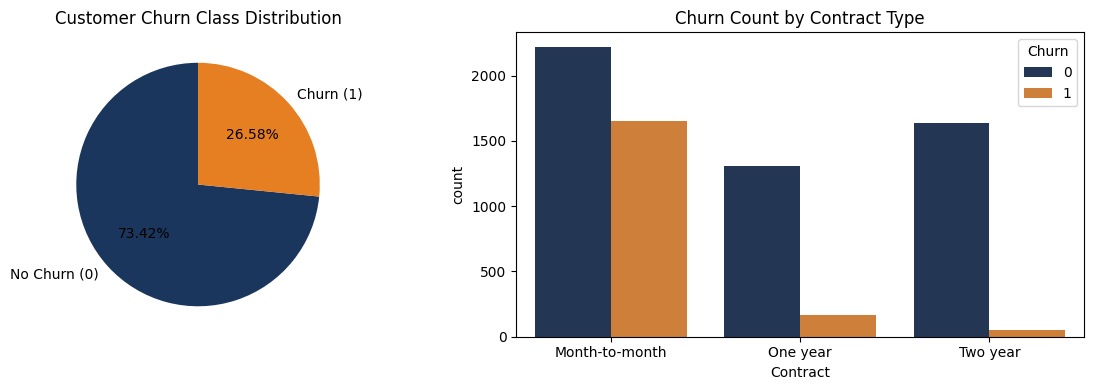

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Churn distribution
churn_counts = df['Churn'].value_counts()
axes[0].pie(churn_counts, labels=['No Churn (0)', 'Churn (1)'], autopct='%1.2f%%', startangle=90, colors=['#1B365D', '#E67E22'])
axes[0].set_title('Customer Churn Class Distribution')

# Churn by Contract Type
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[1], palette=['#1B365D', '#E67E22'])
axes[1].set_title('Churn Count by Contract Type')

plt.tight_layout()
plt.show()

## 3. Feature Encoding, Train-Test Split, Scaling & SMOTE Oversampling

In [57]:
# One-hot encode categorical features
X = pd.get_dummies(df.drop('Churn', axis=1), drop_first=True)
y = df['Churn']

# Stratified train-test split BEFORE SMOTE to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


In [66]:
# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [58]:
# Apply SMOTE strictly on the training set
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", dict(pd.Series(y_train).value_counts()))
print("After SMOTE: ", dict(pd.Series(y_train_res).value_counts()))

Before SMOTE: {0: np.int64(4130), 1: np.int64(1495)}
After SMOTE:  {0: np.int64(4130), 1: np.int64(4130)}


## 4. Supervised ML Benchmarking (Logistic Regression, Random Forest, XGBoost)

Logistic Regression    | Test ROC-AUC: 0.8339
Random Forest          | Test ROC-AUC: 0.8352
Gradient Boosting      | Test ROC-AUC: 0.8342
XGBoost                | Test ROC-AUC: 0.8349


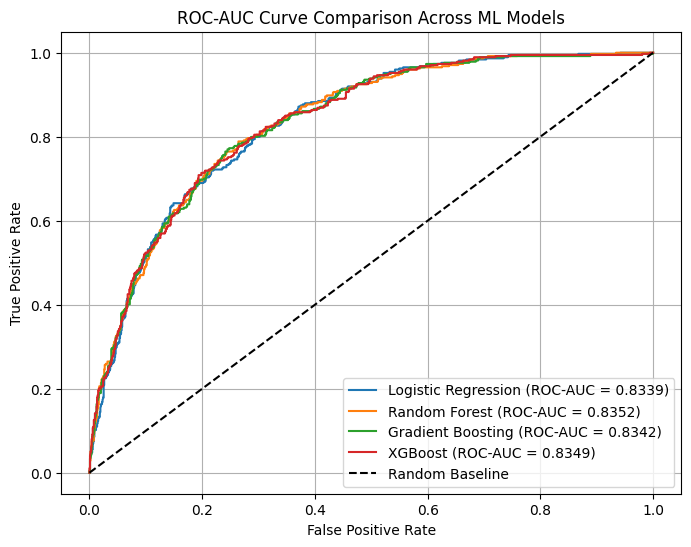

In [59]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=4, eval_metric='logloss', random_state=42)
}

plt.figure(figsize=(8, 6))

for name, clf in models.items():
    clf.fit(X_train_res, y_train_res)
    y_prob = clf.predict_proba(X_test_scaled)[:, 1]
    auc = roc_auc_score(y_test, y_prob)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (ROC-AUC = {auc:.4f})")
    print(f"{name:22s} | Test ROC-AUC: {auc:.4f}")

plt.plot([0, 1], [0, 1], 'k--', label='Random Baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve Comparison Across ML Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## 5. Deep Learning Artificial Neural Network (TensorFlow / Keras)

In [60]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [61]:
tf.random.set_seed(42)
ann_model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_res.shape[1],)),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

ann_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])

history = ann_model.fit(
    X_train_res, y_train_res,
    validation_split=0.15,
    epochs=40,
    batch_size=32,
    verbose=0
)

ann_probs = ann_model.predict(X_test_scaled).ravel()
ann_preds = (ann_probs > 0.5).astype(int)
ann_auc = roc_auc_score(y_test, ann_probs)
print(f"TensorFlow/Keras ANN   | Test ROC-AUC: {ann_auc:.4f}")
print("\nConfusion Matrix (ANN):\n", confusion_matrix(y_test, ann_preds))
print("\nClassification Report (ANN):\n", classification_report(y_test, ann_preds))

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
TensorFlow/Keras ANN   | Test ROC-AUC: 0.8315

Confusion Matrix (ANN):
 [[847 186]
 [133 241]]

Classification Report (ANN):
               precision    recall  f1-score   support

           0       0.86      0.82      0.84      1033
           1       0.56      0.64      0.60       374

    accuracy                           0.77      1407
   macro avg       0.71      0.73      0.72      1407
weighted avg       0.78      0.77      0.78      1407

